## **`EDA `**


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
!ls /content/drive/MyDrive/ML_project_dataset/

EDA_LR.ipynb  submission.csv  test.csv	train.csv  train.ipynb


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print("Training shape:", train.shape)
print("Test shape:", test.shape)

display(train.head())

Saving test.csv to test.csv
Saving train.csv to train.csv
Training shape: (18076, 12)
Test shape: (4520, 11)


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,2856,Southwest,WN 3596,San Jose,Early_Morning,zero,Morning,Los Angeles,Economy,1.33,5,315
1,21812,Southwest,WN 1307,San Jose,Evening,zero,Evening,San Diego,Economy,1.58,40,149
2,476,United,UA 1763,San Diego,Afternoon,zero,Afternoon,San Francisco,Economy,1.77,2,129
3,21802,Southwest,WN 367,San Jose,Morning,zero,Morning,San Diego,Economy,1.58,40,94
4,5099,United,UA 2117,San Diego,Afternoon,zero,Evening,San Francisco,Economy,1.70,9,146


In [ ]:

missing = pd.DataFrame({
    "missing_count": train.isna().sum(),
    "missing_percent": train.isna().mean() * 100
})

missing = missing.sort_values(
    "missing_percent", ascending=False
)

display(missing)

,missing_count,missing_percent
id,0,0.0
airline,0,0.0
flight,0,0.0
source_city,0,0.0
departure_time,0,0.0
stops,0,0.0
arrival_time,0,0.0
destination_city,0,0.0
flight_class,0,0.0
duration,0,0.0


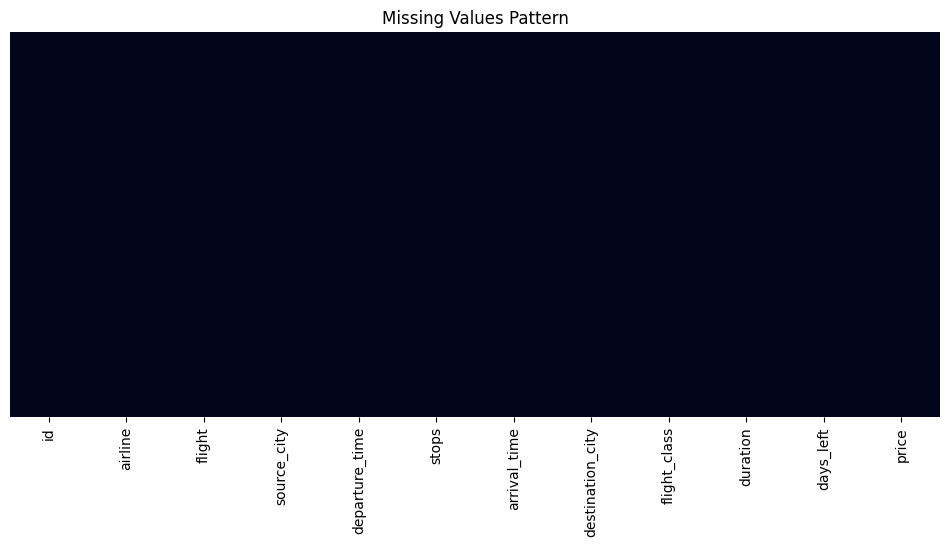

In [ ]:

plt.figure(figsize=(12, 5))
sns.heatmap(train.isna(), cbar=False , yticklabels=False)
plt.title("Missing Values Pattern")
plt.show()

In [ ]:

print("Exact duplicate rows:", train.duplicated().sum())

print("Duplicate IDs:", train["id"].duplicated().sum()
      if "id" in train.columns else "No id column")

display(train[train.duplicated(keep=False)].head(10))

Exact duplicate rows: 0
Duplicate IDs: 0


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price


In [ ]:

display(train.describe().T)

display(train.describe(include="object").T)

,count,mean,std,min,25%,50%,75%,max
id,18076.0,11308.626189,6526.337957,0.00,5668.75,11329.50,16949.5,22595.00
duration,18076.0,2.746853,2.947519,0.87,1.47,1.63,2.0,28.65
days_left,18076.0,20.520912,12.094984,1.00,10.00,20.00,31.0,44.00
price,18076.0,280.264550,221.965133,0.00,157.00,234.00,336.0,8996.00


,count,unique,top,freq
airline,18076,7,Alaska_Airlines,4554
flight,18076,1123,AA 6279,183
source_city,18076,5,Los Angeles,4561
departure_time,18076,6,Morning,5144
stops,18076,3,zero,13559
arrival_time,18076,6,Afternoon,4785
destination_city,18076,5,Los Angeles,4533
flight_class,18076,2,Economy,10711


count    18076.000000
mean       280.264550
std        221.965133
min          0.000000
25%        157.000000
50%        234.000000
75%        336.000000
max       8996.000000
Name: price, dtype: float64


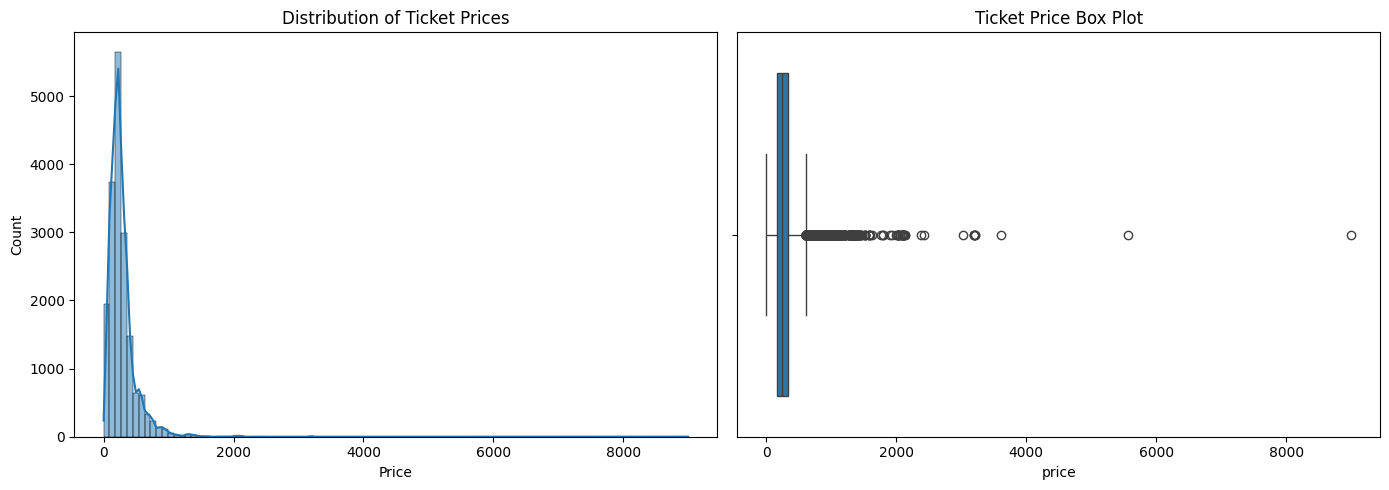

In [ ]:

print(train["price"].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(train["price"].dropna(), bins=100, kde=True,
             ax=axes[0])
axes[0].set_title("Distribution of Ticket Prices")
axes[0].set_xlabel("Price")

sns.boxplot(x=train["price"], ax=axes[1])
axes[1].set_title("Ticket Price Box Plot")

plt.tight_layout()
plt.show()

In [ ]:
# checking for extreme values

q1 = train["price"].quantile(0.25)
q3 = train["price"].quantile(0.75)

iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outliers = train[
    (train["price"] < lower) |
    (train["price"] > upper)
]

print("Lower bound:", lower)
print("Upper bound:", upper)
print("Potential outliers:", len(outliers))

display(
    outliers.sort_values("price", ascending=False).head(10)
)

Lower bound: -111.5
Upper bound: 604.5
Potential outliers: 1120


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
15787,16,United,UA 729,Los Angeles,Late_Night,one,Morning,San Diego,Business,9.37,1,8996
15200,22275,Alaska_Airlines,AS 2224,San Diego,Night,one,Afternoon,San Jose,Business,14.52,43,5564
5936,19925,Alaska_Airlines,AS 668,Los Angeles,Early_Morning,one,Afternoon,San Jose,Business,5.58,37,3607
12601,11469,United,UA 1055,Sacramento,Morning,one,Evening,San Jose,Business,6.70,19,3204
2473,13008,United,UA 1055,Sacramento,Morning,one,Evening,San Jose,Business,6.70,23,3204
4249,7975,United,UA 1055,Sacramento,Morning,one,Evening,San Jose,Business,6.70,14,3194
10611,5522,United,UA 2013,San Jose,Morning,one,Afternoon,Sacramento,Business,6.28,10,3194
12674,5650,United,UA 1023,Sacramento,Morning,one,Evening,San Jose,Business,6.70,10,3194
7528,4233,United,UA 1100,San Diego,Night,one,Morning,San Jose,Business,13.27,9,3029
12109,19085,United,UA 2013,San Jose,Morning,one,Afternoon,Sacramento,Business,6.43,37,2424


In [ ]:

# Inspect tickets with zero price
zero_price = train[train["price"] == 0]

print("Number of zero-price tickets:", len(zero_price))
display(zero_price)

Number of zero-price tickets: 25


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
346,7703,Southwest,WN 2847,San Jose,Afternoon,one,Afternoon,Sacramento,Economy,3.25,13,0
934,12440,Southwest,WN 3903,Sacramento,Afternoon,one,Evening,San Jose,Economy,3.17,25,0
1352,13813,Southwest,WN 3797,San Jose,Morning,one,Afternoon,Sacramento,Economy,3.25,21,0
2762,4900,Southwest,WN 2847,San Jose,Afternoon,one,Afternoon,Sacramento,Economy,3.25,10,0
3101,5689,Southwest,WN 3687,Sacramento,Evening,one,Night,San Jose,Economy,3.08,9,0
4350,3307,Southwest,WN 2864,Sacramento,Morning,one,Morning,San Jose,Economy,3.08,6,0
5386,7879,Southwest,WN 3684,Sacramento,Morning,one,Afternoon,San Jose,Economy,3.08,15,0
5600,9839,Southwest,WN 2847,San Jose,Afternoon,one,Afternoon,Sacramento,Economy,3.25,16,0
5991,17620,Alaska_Airlines,AS 490,Sacramento,Early_Morning,one,Morning,San Jose,Economy,4.33,35,0
6642,4923,Southwest,WN 2864,Sacramento,Morning,one,Morning,San Jose,Economy,3.08,10,0


In [ ]:

display(
    train.groupby("flight_class")["price"]
    .agg(["count", "mean", "median", "min", "max"])
)

,count,mean,median,min,max
flight_class,,,,,
Business,7365,393.955465,323.0,0,8996
Economy,10711,202.089441,194.0,0,1071


In [ ]:

print(train["airline"].value_counts())

airline
Alaska_Airlines             4554
United                      4058
Southwest                   3895
Delta                       2972
American_Airlines           1797
Frontier                     799
Southern_Airways_Express       1
Name: count, dtype: int64


In [ ]:

display(
    train.groupby("airline")["price"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("median", ascending=False)
)

,count,mean,median,min,max
airline,,,,,
Southern_Airways_Express,1,543.000000,543.0,543,543
Delta,2972,286.528264,259.0,79,1472
Alaska_Airlines,4554,302.619895,259.0,0,5564
United,4058,319.028586,259.0,69,8996
American_Airlines,1797,349.440178,253.0,59,2025
Southwest,3895,197.837227,199.0,0,871
Frontier,799,178.583229,168.0,19,650


In [ ]:
#flight stops

print(train["stops"].value_counts())

stops
zero           13559
one             4324
two_or_more      193
Name: count, dtype: int64


In [ ]:
#Comparing stops by prices
display(
    train.groupby("stops")["price"]
    .agg(["count", "mean", "median", "min", "max"])
)

,count,mean,median,min,max
stops,,,,,
one,4324,431.533996,347.0,0,8996
two_or_more,193,425.735751,370.0,97,1233
zero,13559,229.953684,214.0,19,2025


In [ ]:

display(train[["duration", "days_left", "price"]].describe().T)

,count,mean,std,min,25%,50%,75%,max
duration,18076.0,2.746853,2.947519,0.87,1.47,1.63,2.0,28.65
days_left,18076.0,20.520912,12.094984,1.00,10.00,20.00,31.0,44.00
price,18076.0,280.264550,221.965133,0.00,157.00,234.00,336.0,8996.00


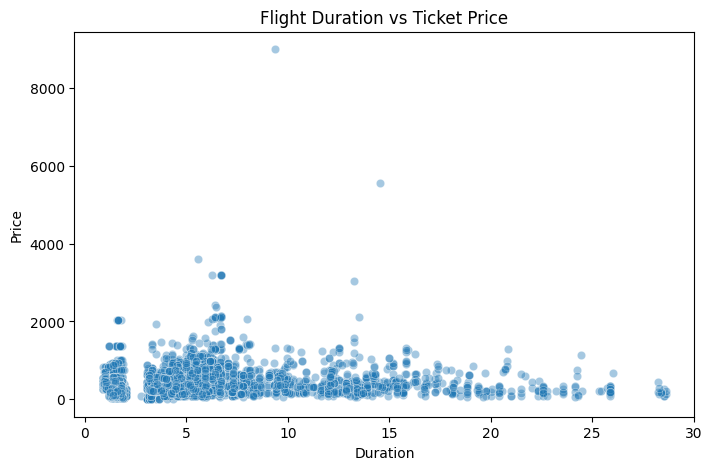

In [ ]:

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=train,
    x="duration",
    y="price",
    alpha=0.4
)
plt.title("Flight Duration vs Ticket Price")
plt.xlabel("Duration")
plt.ylabel("Price")
plt.show()

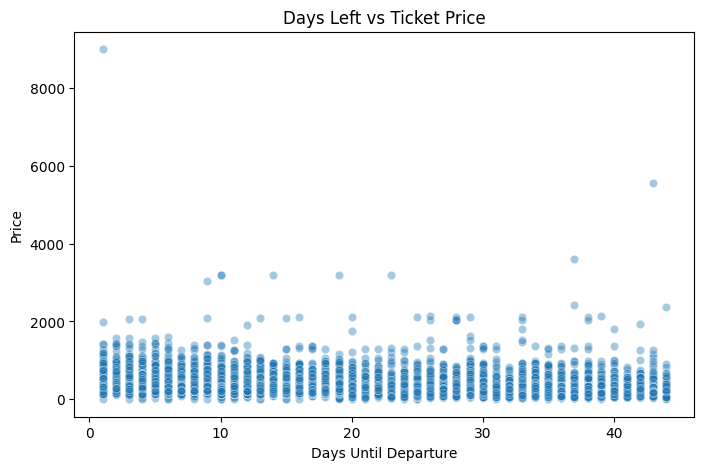

In [ ]:

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=train,
    x="days_left",
    y="price",
    alpha=0.4
)
plt.title("Days Left vs Ticket Price")
plt.xlabel("Days Until Departure")
plt.ylabel("Price")
plt.show()

In [ ]:

train["days_left_group"] = pd.cut(
    train["days_left"],
    bins=[0, 7, 14, 21, 30, 45, 100],
    labels=["1-7", "8-14", "15-21", "22-30", "31-45", "46+"]
)

display(
    train.groupby("days_left_group", observed=True)["price"]
    .agg(["count", "mean", "median"])
)

,count,mean,median
days_left_group,,,
1-7,3273,363.183624,307.0
8-14,3333,324.851485,262.0
15-21,3246,276.636168,234.0
22-30,3657,243.101723,199.0
31-45,4567,220.636742,179.0


In [ ]:

display(
    train.pivot_table(
        index="days_left_group",
        columns="flight_class",
        values="price",
        aggfunc="median"
    )
)

/tmp/ipykernel_666/3157819087.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  train.pivot_table(


flight_class,Business,Economy
days_left_group,,
1-7,375.0,259.0
8-14,329.0,224.0
15-21,297.0,189.0
22-30,294.0,139.0
31-45,285.0,109.0


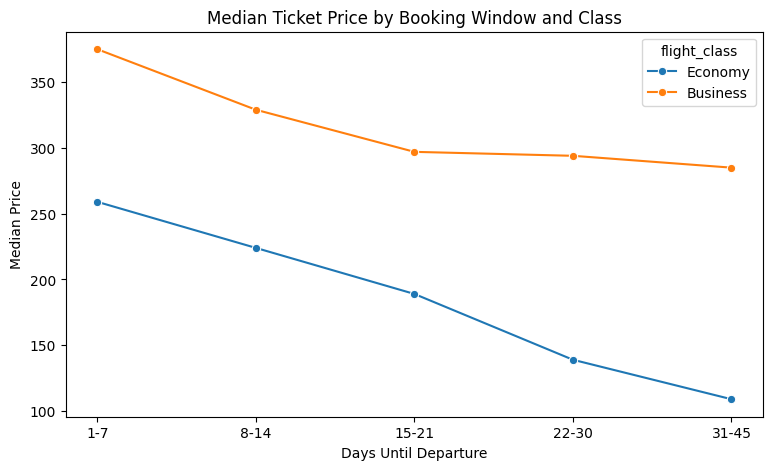

In [ ]:

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=train,
    x="days_left_group",
    y="price",
    hue="flight_class",
    estimator="median",
    errorbar=None,
    marker="o"
)

plt.title("Median Ticket Price by Booking Window and Class")
plt.xlabel("Days Until Departure")
plt.ylabel("Median Price")
plt.show()

In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = ["duration", "days_left", "price"]

corr = train[numeric_cols].corr()

print(corr.round(3).to_json())

{"duration":{"duration":1.0,"days_left":-0.018,"price":0.281},"days_left":{"duration":-0.018,"days_left":1.0,"price":-0.229},"price":{"duration":0.281,"days_left":-0.229,"price":1.0}}


In [ ]:
categorical_cols = [
    "airline",
    "source_city",
    "departure_time",
    "stops",
    "arrival_time",
    "destination_city",
    "flight_class"
]

summary = {}

for col in categorical_cols:
    counts = train[col].value_counts()

    summary[col] = {
        "unique_categories": int(train[col].nunique()),
        "category_counts": {
            str(k): int(v)
            for k, v in counts.items()
        }
    }

print(json.dumps(summary, indent=2))

{
  "airline": {
    "unique_categories": 7,
    "category_counts": {
      "Alaska_Airlines": 4554,
      "United": 4058,
      "Southwest": 3895,
      "Delta": 2972,
      "American_Airlines": 1797,
      "Frontier": 799,
      "Southern_Airways_Express": 1
    }
  },
  "source_city": {
    "unique_categories": 5,
    "category_counts": {
      "Los Angeles": 4561,
      "San Francisco": 4086,
      "San Diego": 3691,
      "Sacramento": 3521,
      "San Jose": 2217
    }
  },
  "departure_time": {
    "unique_categories": 6,
    "category_counts": {
      "Morning": 5144,
      "Evening": 4436,
      "Afternoon": 3893,
      "Early_Morning": 2820,
      "Night": 1777,
      "Late_Night": 6
    }
  },
  "stops": {
    "unique_categories": 3,
    "category_counts": {
      "zero": 13559,
      "one": 4324,
      "two_or_more": 193
    }
  },
  "arrival_time": {
    "unique_categories": 6,
    "category_counts": {
      "Afternoon": 4785,
      "Evening": 4549,
      "Morning": 4364,


In [ ]:
route_stats = (
    train.groupby(["source_city", "destination_city"])["price"]
    .agg(["count", "median", "mean"])
    .reset_index()
    .sort_values("count", ascending=False)
)

print(
    route_stats.head(15).round(2).to_json(orient="records")
)

[{"source_city":"San Francisco","destination_city":"Los Angeles","count":2065,"median":207.0,"mean":235.31},{"source_city":"Los Angeles","destination_city":"San Francisco","count":1995,"median":207.0,"mean":232.78},{"source_city":"San Francisco","destination_city":"San Diego","count":1305,"median":149.0,"mean":189.5},{"source_city":"San Diego","destination_city":"San Francisco","count":1257,"median":149.0,"mean":190.04},{"source_city":"Sacramento","destination_city":"Los Angeles","count":990,"median":222.0,"mean":237.08},{"source_city":"Los Angeles","destination_city":"Sacramento","count":977,"median":222.0,"mean":237.81},{"source_city":"Sacramento","destination_city":"San Jose","count":872,"median":535.5,"mean":583.65},{"source_city":"Los Angeles","destination_city":"San Diego","count":847,"median":328.0,"mean":344.09},{"source_city":"San Diego","destination_city":"Sacramento","count":847,"median":224.0,"mean":216.35},{"source_city":"Sacramento","destination_city":"San Diego","count":

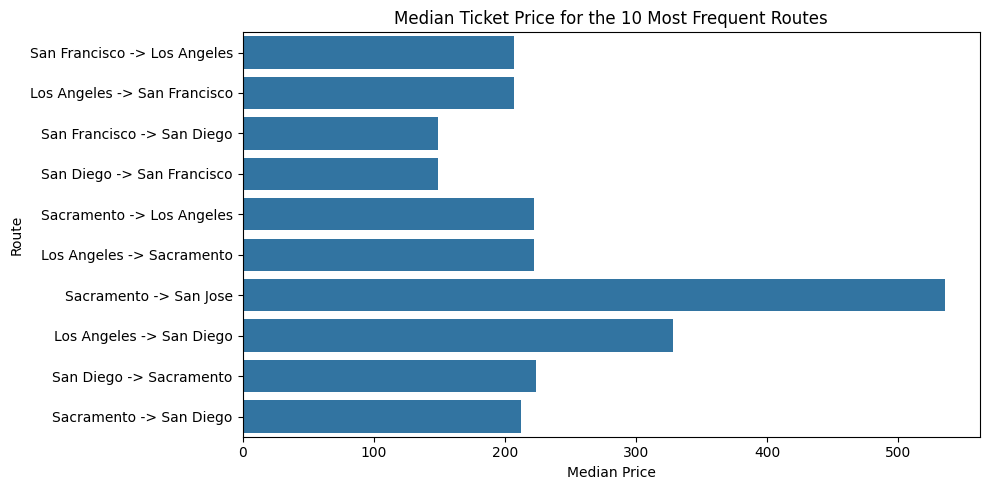

[{"route":"San Francisco -> Los Angeles","count":2065,"median":207.0},{"route":"Los Angeles -> San Francisco","count":1995,"median":207.0},{"route":"San Francisco -> San Diego","count":1305,"median":149.0},{"route":"San Diego -> San Francisco","count":1257,"median":149.0},{"route":"Sacramento -> Los Angeles","count":990,"median":222.0},{"route":"Los Angeles -> Sacramento","count":977,"median":222.0},{"route":"Sacramento -> San Jose","count":872,"median":535.5},{"route":"Los Angeles -> San Diego","count":847,"median":328.0},{"route":"San Diego -> Sacramento","count":847,"median":224.0},{"route":"Sacramento -> San Diego","count":838,"median":212.0}]


In [ ]:
top_routes = route_stats.head(10).copy()

top_routes["route"] = (
    top_routes["source_city"]
    + " -> "
    + top_routes["destination_city"]
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=top_routes,
    x="median",
    y="route"
)

plt.title("Median Ticket Price for the 10 Most Frequent Routes")
plt.xlabel("Median Price")
plt.ylabel("Route")
plt.tight_layout()
plt.show()

# Compact data behind the plot
plot_data = top_routes[["route", "count", "median"]].copy()
plot_data["median"] = plot_data["median"].round(2)

print(plot_data.to_json(orient="records"))


In [ ]:

print("Shape:", train.shape)
print("Columns:", train.columns.tolist())
print("\nTarget summary:")
print(train["price"].describe())

print("\nTest shape:", test.shape)
print("Test columns:", test.columns.tolist())

Shape: (18076, 13)
Columns: ['id', 'airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class', 'duration', 'days_left', 'price', 'days_left_group']

Target summary:
count    18076.000000
mean       280.264550
std        221.965133
min          0.000000
25%        157.000000
50%        234.000000
75%        336.000000
max       8996.000000
Name: price, dtype: float64

Test shape: (4520, 11)
Test columns: ['id', 'airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class', 'duration', 'days_left']


In [ ]:

from sklearn.model_selection import train_test_split

target = "price"

# Exclude the target and identifier-like columns from model features.
drop_cols = ["price", "id"]

# Drop index only if it is present and is just a saved row index.
if "index" in train.columns:
    drop_cols.append("index")

X = train.drop(columns=drop_cols, errors="ignore").copy()
y = train[target].copy()

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Feature columns:", X.columns.tolist())
print("Training rows:", X_train.shape[0])
print("Validation rows:", X_val.shape[0])

Feature columns: ['airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class', 'duration', 'days_left', 'days_left_group']
Training rows: 14460
Validation rows: 3616


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['duration', 'days_left']
Categorical features: ['airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class', 'days_left_group']


**DATA PRE-PROCESSING**

In [ ]:


print("TRAIN SHAPE:", train.shape)
print("TEST SHAPE:", test.shape)

print("\nTRAIN COLUMNS:")
print(train.columns.tolist())

print("\nTEST COLUMNS:")
print(test.columns.tolist())

print("\nFIRST 5 TRAINING ROWS:")
display(train.head())

print("\nDATA TYPES:")
print(train.dtypes)

print("\nTARGET CHECK:")
print("Does train contain price?", "price" in train.columns)
print("Does test contain price?", "price" in test.columns)

print("\nID CHECK:")
print("Train IDs unique:", train["id"].is_unique)
print("Test IDs unique:", test["id"].is_unique)


TRAIN SHAPE: (18076, 13)
TEST SHAPE: (4520, 11)

TRAIN COLUMNS:
['id', 'airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class', 'duration', 'days_left', 'price', 'days_left_group']

TEST COLUMNS:
['id', 'airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class', 'duration', 'days_left']

FIRST 5 TRAINING ROWS:


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price,days_left_group
0,2856,Southwest,WN 3596,San Jose,Early_Morning,zero,Morning,Los Angeles,Economy,1.33,5,315,1-7
1,21812,Southwest,WN 1307,San Jose,Evening,zero,Evening,San Diego,Economy,1.58,40,149,31-45
2,476,United,UA 1763,San Diego,Afternoon,zero,Afternoon,San Francisco,Economy,1.77,2,129,1-7
3,21802,Southwest,WN 367,San Jose,Morning,zero,Morning,San Diego,Economy,1.58,40,94,31-45
4,5099,United,UA 2117,San Diego,Afternoon,zero,Evening,San Francisco,Economy,1.70,9,146,8-14



DATA TYPES:
id                     int64
airline               object
flight                object
source_city           object
departure_time        object
stops                 object
arrival_time          object
destination_city      object
flight_class          object
duration             float64
days_left              int64
price                  int64
days_left_group     category
dtype: object

TARGET CHECK:
Does train contain price? True
Does test contain price? False

ID CHECK:
Train IDs unique: True
Test IDs unique: True


In [ ]:

# STEP 2: Investigate index and flight

if "index" in train.columns:
    print("INDEX COLUMN")
    print("First 10 values:", train["index"].head(10).tolist())
    print("Unique values:", train["index"].nunique())
    print(
        "Matches sequential row numbers:",
        train["index"].reset_index(drop=True).equals(
            __import__("pandas").Series(range(len(train)))
        )
    )
else:
    print("No 'index' column found.")

print("\n" + "=" * 45)

if "flight" in train.columns:
    print("FLIGHT COLUMN")
    print("Unique flight codes:", train["flight"].nunique())
    print("Total training rows:", len(train))
    print("\nMost frequent flight codes:")
    print(train["flight"].value_counts().head(15))

    print(
        "\nFlight codes appearing only once:",
        (train["flight"].value_counts() == 1).sum()
    )
else:
    print("No 'flight' column found.")


No 'index' column found.

FLIGHT COLUMN
Unique flight codes: 1123
Total training rows: 18076

Most frequent flight codes:
flight
AA 6279    183
DL 3716    156
DL 3883    149
AA 1358    144
DL 4087    141
DL 3755    136
AA 6278    130
DL 3712    130
AA 6277    129
DL 3700    125
DL 1421    122
DL 3812    121
AA 6276    121
DL 3759    120
DL 3842    120
Name: count, dtype: int64

Flight codes appearing only once: 180


In [ ]:

from sklearn.model_selection import train_test_split

# Target variable
y = train["price"]

# Keep id for submission, but exclude it from model features.
# Exclude flight in our initial experiment.
excluded_columns = ["price", "id", "flight"]

X = train.drop(columns=excluded_columns)
X_test = test.drop(columns=["id", "flight"])

# Identify numerical and categorical columns automatically
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Features used:", X.columns.tolist())
print("\nNumerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

# Fixed validation split
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining split:", X_train.shape)
print("Validation split:", X_val.shape)
print("Test data:", X_test.shape)


Features used: ['airline', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class', 'duration', 'days_left', 'days_left_group']

Numerical features: ['duration', 'days_left']

Categorical features: ['airline', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class', 'days_left_group']

Training split: (14460, 10)
Validation split: (3616, 10)
Test data: (4520, 9)


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing branches
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessing pipeline created successfully.")
print("Numerical columns:", len(numeric_features))
print("Categorical columns:", len(categorical_features))


Preprocessing pipeline created successfully.
Numerical columns: 2
Categorical columns: 8


In [ ]:

import numpy as np
import pandas as pd

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Store all model results in one place
results = []

def evaluate_model(model_name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    print(f"Model: {model_name}")
    print(f"MAE:  {mae:.3f}")
    print(f"RMSE: {rmse:.3f}")
    print(f"R²:   {r2:.4f}")


**BASELINE** **REGRESSION** **MODEL**

In [ ]:

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

# MODEL 1: Mean baseline
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_val)

evaluate_model(
    "Mean Baseline",
    y_val,
    baseline_predictions
)

print("\n" + "=" * 40 + "\n")

# MODEL 2: Multiple Linear Regression
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_val)

evaluate_model(
    "Multiple Linear Regression",
    y_val,
    linear_predictions
)

print("\nCURRENT MODEL COMPARISON")
display(pd.DataFrame(results).round(4))


Model: Mean Baseline
MAE:  139.649
RMSE: 237.281
R²:   -0.0008


Model: Multiple Linear Regression
MAE:  93.240
RMSE: 181.456
R²:   0.4147

CURRENT MODEL COMPARISON


,Model,MAE,RMSE,R2
0,Mean Baseline,139.6487,237.2814,-0.0008
1,Multiple Linear Regression,93.2400,181.4556,0.4147


**POLYNOMIAL REGRESSION (DEGREES 2-8)**

In [ ]:

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [ ]:

poly_results = []
poly_models = {}

for degree in range(2, 9):

    # Polynomial transformations for numerical features
    numeric_poly = Pipeline(steps=[
        ("poly", PolynomialFeatures(
            degree=degree,
            include_bias=False
        )),
        ("scaler", StandardScaler())
    ])

    # Keep categorical features one-hot encoded
    categorical_transformer = OneHotEncoder(
        handle_unknown="ignore"
    )

    # Combine numerical polynomial features and categorical features
    poly_preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_poly, numeric_features),
            ("cat", categorical_transformer, categorical_features)
        ]
    )

    # Complete polynomial regression model
    model = Pipeline(steps=[
        ("preprocessor", poly_preprocessor),
        ("regressor", LinearRegression())
    ])

    # Train on the same training split
    model.fit(X_train, y_train)

    # Evaluate on the same validation split
    predictions = model.predict(X_val)

    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    r2 = r2_score(y_val, predictions)

    poly_results.append({
        "Model": f"Polynomial Degree {degree}",
        "Degree": degree,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    poly_models[degree] = model

    print(
        f"Degree {degree} | "
        f"MAE: {mae:.3f} | "
        f"RMSE: {rmse:.3f} | "
        f"R2: {r2:.4f}"
    )

poly_results_df = pd.DataFrame(poly_results)

print("\nPOLYNOMIAL REGRESSION COMPARISON")
display(
    poly_results_df.sort_values("RMSE").round(4)
)


Degree 2 | MAE: 92.706 | RMSE: 180.902 | R2: 0.4183
Degree 3 | MAE: 91.630 | RMSE: 180.117 | R2: 0.4233
Degree 4 | MAE: 89.817 | RMSE: 178.894 | R2: 0.4311
Degree 5 | MAE: 88.682 | RMSE: 177.837 | R2: 0.4378
Degree 6 | MAE: 87.412 | RMSE: 177.135 | R2: 0.4422
Degree 7 | MAE: 86.746 | RMSE: 177.025 | R2: 0.4429
Degree 8 | MAE: 86.435 | RMSE: 176.260 | R2: 0.4477

POLYNOMIAL REGRESSION COMPARISON


,Model,Degree,MAE,RMSE,R2
6,Polynomial Degree 8,8,86.4351,176.2595,0.4477
5,Polynomial Degree 7,7,86.7461,177.0254,0.4429
4,Polynomial Degree 6,6,87.4116,177.1349,0.4422
3,Polynomial Degree 5,5,88.6816,177.8374,0.4378
2,Polynomial Degree 4,4,89.8174,178.8937,0.4311
1,Polynomial Degree 3,3,91.6299,180.1173,0.4233
0,Polynomial Degree 2,2,92.7062,180.9021,0.4183


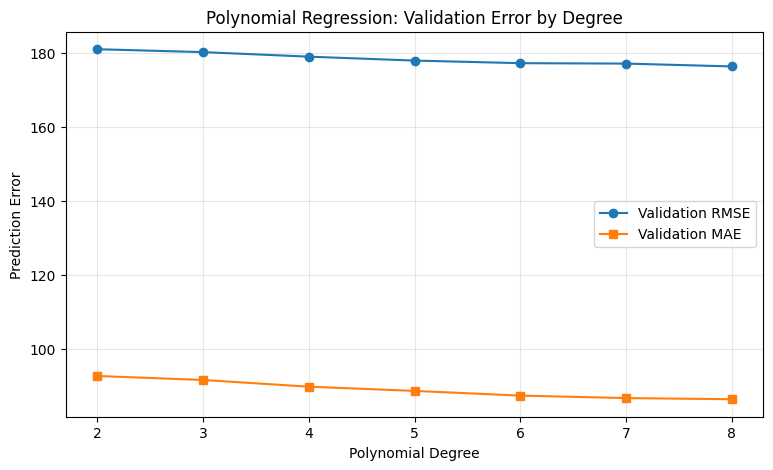

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    poly_results_df["Degree"],
    poly_results_df["RMSE"],
    marker="o",
    label="Validation RMSE"
)

plt.plot(
    poly_results_df["Degree"],
    poly_results_df["MAE"],
    marker="s",
    label="Validation MAE"
)

plt.xticks(range(2, 9))
plt.xlabel("Polynomial Degree")
plt.ylabel("Prediction Error")
plt.title("Polynomial Regression: Validation Error by Degree")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


**MODEL COMPARISON OF MLR AND POLYNOMIAL REGRESSION(2-8)**

In [ ]:

# Compare Multiple Linear Regression + Polynomial Degrees 2–8

comparison_models = {
    "Multiple Linear": linear_model
}

for degree, model in poly_models.items():
    comparison_models[f"Polynomial Degree {degree}"] = model

comparison_data = []

for name, model in comparison_models.items():

    # Predictions on training data
    train_predictions = model.predict(X_train)

    # Predictions on validation data
    val_predictions = model.predict(X_val)

    comparison_data.append({
        "Model": name,
        "Train MAE": mean_absolute_error(y_train, train_predictions),
        "Validation MAE": mean_absolute_error(y_val, val_predictions),
        "Train RMSE": np.sqrt(mean_squared_error(y_train, train_predictions)),
        "Validation RMSE": np.sqrt(mean_squared_error(y_val, val_predictions)),
        "Train R2": r2_score(y_train, train_predictions),
        "Validation R2": r2_score(y_val, val_predictions)
    })

comparison_df = pd.DataFrame(comparison_data)

display(
    comparison_df.sort_values("Validation RMSE").round(4)
)


,Model,Train MAE,Validation MAE,Train RMSE,Validation RMSE,Train R2,Validation R2
7,Polynomial Degree 8,80.6304,86.4351,147.3658,176.2595,0.5429,0.4477
6,Polynomial Degree 7,80.9950,86.7461,147.6641,177.0254,0.5410,0.4429
5,Polynomial Degree 6,82.0079,87.4116,148.3808,177.1349,0.5366,0.4422
4,Polynomial Degree 5,83.1327,88.6816,149.5095,177.8374,0.5295,0.4378
3,Polynomial Degree 4,83.9772,89.8174,150.4851,178.8937,0.5233,0.4311
2,Polynomial Degree 3,85.4744,91.6299,151.3559,180.1173,0.5178,0.4233
1,Polynomial Degree 2,86.4145,92.7062,151.9881,180.9021,0.5138,0.4183
0,Multiple Linear,86.8183,93.2400,152.6941,181.4556,0.5092,0.4147


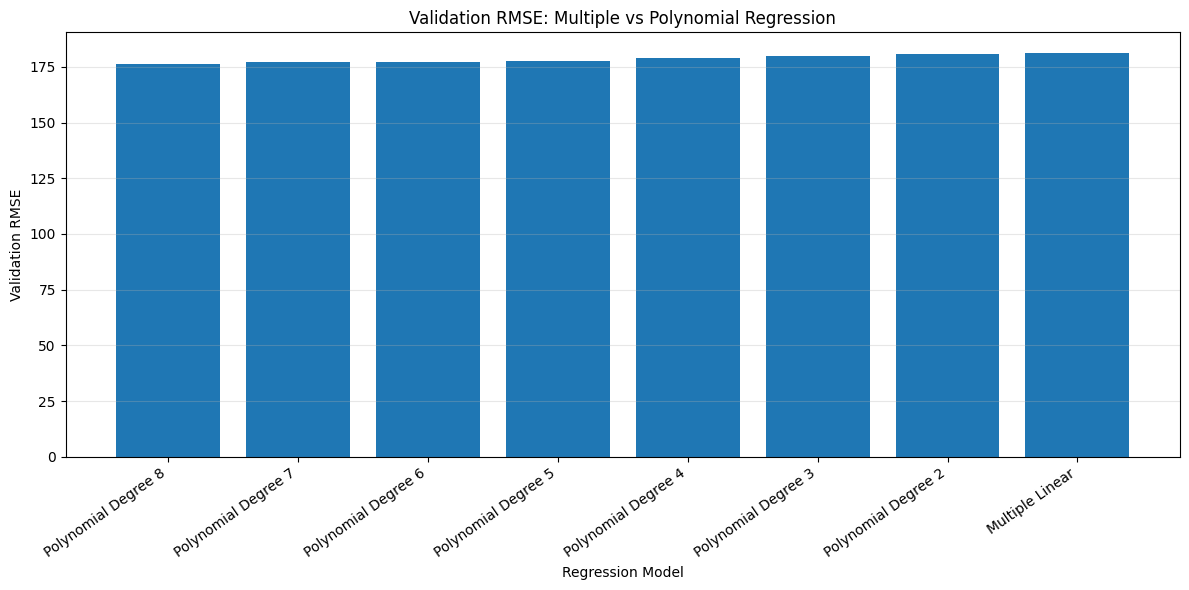

In [ ]:

import matplotlib.pyplot as plt

plot_df = comparison_df.sort_values("Validation RMSE")

plt.figure(figsize=(12, 6))

plt.bar(
    plot_df["Model"],
    plot_df["Validation RMSE"]
)

plt.ylabel("Validation RMSE")
plt.xlabel("Regression Model")
plt.title("Validation RMSE: Multiple vs Polynomial Regression")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


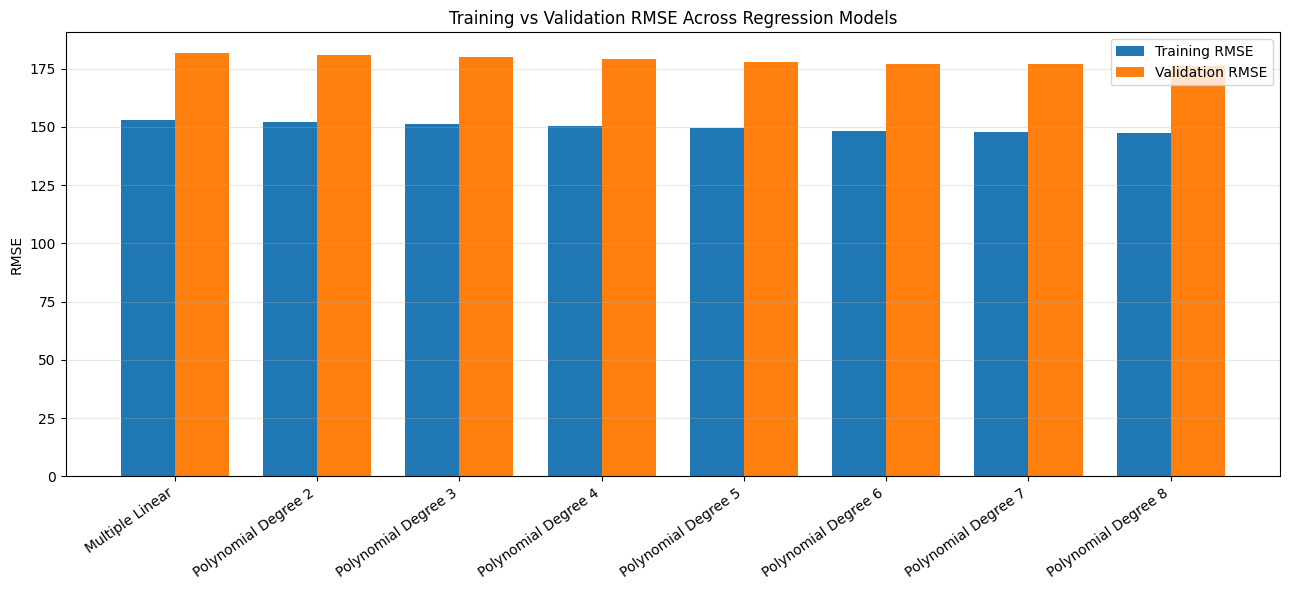

In [ ]:

plot_df = comparison_df.sort_values("Model")

x = np.arange(len(plot_df))
width = 0.38

plt.figure(figsize=(13, 6))

plt.bar(
    x - width / 2,
    plot_df["Train RMSE"],
    width,
    label="Training RMSE"
)

plt.bar(
    x + width / 2,
    plot_df["Validation RMSE"],
    width,
    label="Validation RMSE"
)

plt.xticks(x, plot_df["Model"], rotation=35, ha="right")
plt.ylabel("RMSE")
plt.title("Training vs Validation RMSE Across Regression Models")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


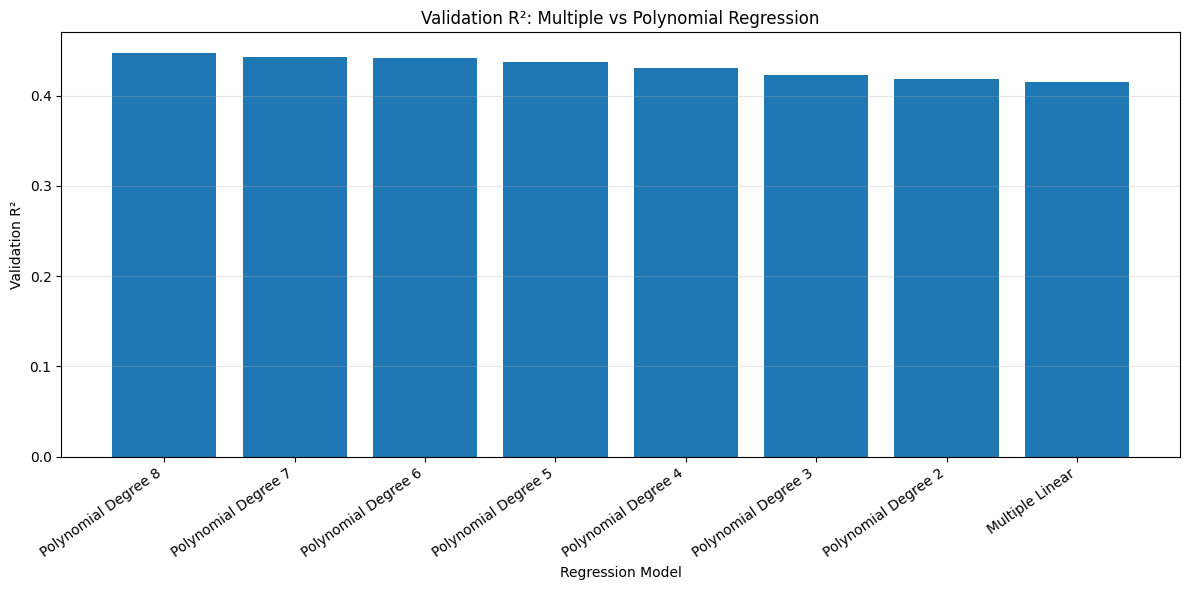

In [ ]:

plot_df = comparison_df.sort_values("Validation R2", ascending=False)

plt.figure(figsize=(12, 6))

plt.bar(
    plot_df["Model"],
    plot_df["Validation R2"]
)

plt.ylabel("Validation R²")
plt.xlabel("Regression Model")
plt.title("Validation R²: Multiple vs Polynomial Regression")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


**RIDGE AND LASSO REGRESSION**

In [ ]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

regularized_results = []
regularized_models = {}

degrees = [2, 4, 6, 8]
ridge_alphas = [0.01, 0.1, 1, 10, 100]
lasso_alphas = [0.1, 1, 10, 100]

for degree in degrees:
    for model_type, alphas in [
        ("Ridge", ridge_alphas),
        ("Lasso", lasso_alphas)
    ]:
        for alpha in alphas:

            numeric_poly = Pipeline(steps=[
                ("poly", PolynomialFeatures(
                    degree=degree,
                    include_bias=False
                )),
                ("scaler", StandardScaler())
            ])

            categorical_transformer = OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )

            poly_preprocessor = ColumnTransformer(
                transformers=[
                    ("num", numeric_poly, numeric_features),
                    ("cat", categorical_transformer, categorical_features)
                ]
            )

            if model_type == "Ridge":
                regressor = Ridge(alpha=alpha)
            else:
                  regressor = Lasso(
                  alpha=alpha,
                  max_iter=50000,
                  tol=1e-3,
                  selection="cyclic"
              )

            model = Pipeline(steps=[
                ("preprocessor", poly_preprocessor),
                ("regressor", regressor)
            ])

            model.fit(X_train, y_train)

            train_pred = model.predict(X_train)
            val_pred = model.predict(X_val)

            regularized_results.append({
                "Model": model_type,
                "Degree": degree,
                "Alpha": alpha,
                "Train_RMSE": np.sqrt(
                    mean_squared_error(y_train, train_pred)
                ),
                "Validation_RMSE": np.sqrt(
                    mean_squared_error(y_val, val_pred)
                ),
                "Train_MAE": mean_absolute_error(y_train, train_pred),
                "Validation_MAE": mean_absolute_error(y_val, val_pred),
                "Train_R2": r2_score(y_train, train_pred),
                "Validation_R2": r2_score(y_val, val_pred)
            })

            model_name = f"{model_type}_degree{degree}_alpha{alpha}"
            regularized_models[model_name] = model

regularized_df = pd.DataFrame(regularized_results)

display(
    regularized_df
    .sort_values("Validation_RMSE")
    .round(4)
    .reset_index(drop=True)
)

,Model,Degree,Alpha,Train_RMSE,Validation_RMSE,Train_MAE,Validation_MAE,Train_R2,Validation_R2
0,Ridge,6,0.01,149.3247,177.9208,82.9186,88.4825,0.5307,0.4373
1,Ridge,8,0.01,148.8134,177.9508,82.4276,88.1057,0.5339,0.4371
2,Ridge,6,0.10,149.8451,178.4142,83.4523,89.2694,0.5274,0.4342
3,Ridge,8,0.10,149.5751,178.4943,83.1697,89.0388,0.5291,0.4337
4,Ridge,6,1.00,150.5610,178.8140,84.1311,90.2263,0.5229,0.4316
5,Ridge,4,0.01,150.4851,178.8945,83.9822,89.8292,0.5233,0.4311
6,Ridge,4,0.10,150.4909,178.9025,84.0240,89.9244,0.5233,0.4311
7,Ridge,8,1.00,150.4153,178.9322,83.9856,90.0960,0.5238,0.4309
8,Ridge,6,10.00,153.3025,178.9399,84.7713,91.1295,0.5053,0.4308
9,Ridge,4,1.00,150.7289,178.9988,84.3414,90.4711,0.5218,0.4304


**COMPARING REGULARIZATION AND POLYNOMIAL MODELS**

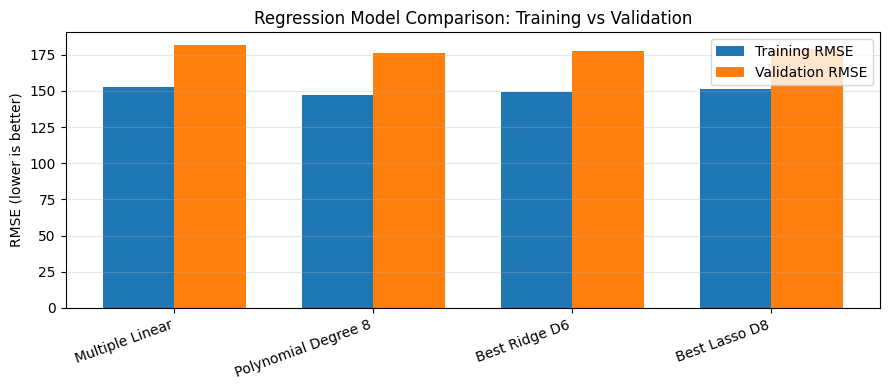

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Best model from each family
best_ridge = regularized_df[
    regularized_df["Model"] == "Ridge"
].sort_values("Validation_RMSE").iloc[0]

best_lasso = regularized_df[
    regularized_df["Model"] == "Lasso"
].sort_values("Validation_RMSE").iloc[0]

comparison = {
    "Multiple Linear": linear_model,
    "Polynomial Degree 8": poly_models[8],
    f"Best Ridge D{int(best_ridge['Degree'])}": regularized_models[
        f"Ridge_degree{int(best_ridge['Degree'])}_alpha{best_ridge['Alpha']}"
    ],
    f"Best Lasso D{int(best_lasso['Degree'])}": regularized_models[
        f"Lasso_degree{int(best_lasso['Degree'])}_alpha{best_lasso['Alpha']}"
    ]
}

names = []
train_rmse = []
val_rmse = []

for name, model in comparison.items():
    names.append(name)

    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    train_rmse.append(
        np.sqrt(mean_squared_error(y_train, train_pred))
    )
    val_rmse.append(
        np.sqrt(mean_squared_error(y_val, val_pred))
    )

x = np.arange(len(names))
width = 0.36

plt.figure(figsize=(9, 4))
plt.bar(x - width/2, train_rmse, width, label="Training RMSE")
plt.bar(x + width/2, val_rmse, width, label="Validation RMSE")

plt.xticks(x, names, rotation=20, ha="right")
plt.ylabel("RMSE (lower is better)")
plt.title("Regression Model Comparison: Training vs Validation")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

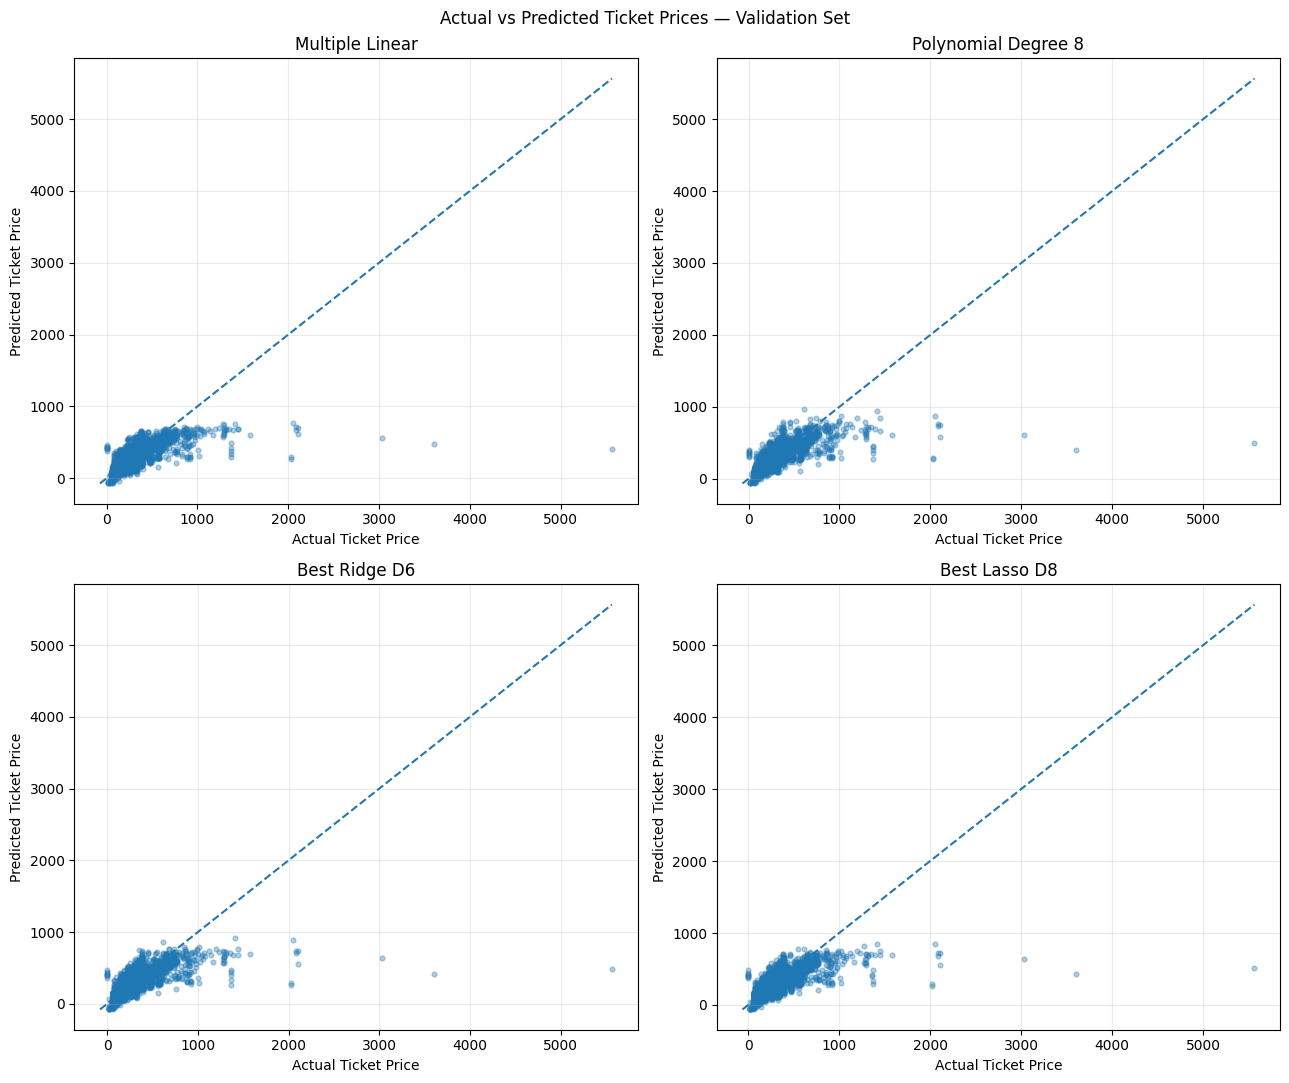

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11))

for ax, (name, model) in zip(axes.ravel(), comparison.items()):
    predictions = model.predict(X_val)

    ax.scatter(y_val, predictions, alpha=0.35, s=12)

    lower = min(y_val.min(), predictions.min())
    upper = max(y_val.max(), predictions.max())

    ax.plot(
        [lower, upper],
        [lower, upper],
        linestyle="--"
    )

    ax.set_title(name)
    ax.set_xlabel("Actual Ticket Price")
    ax.set_ylabel("Predicted Ticket Price")
    ax.grid(alpha=0.25)

plt.suptitle("Actual vs Predicted Ticket Prices — Validation Set")
plt.tight_layout()
plt.show()

**LOG TARGET POLYNOMIAL OF DEGREE 8**

In [ ]:
from sklearn.base import clone

log_poly_model = clone(poly_models[8])

# Transform the target, then train the existing Degree 8 pipeline
y_train_log = np.log1p(y_train)

log_poly_model.fit(X_train, y_train_log)

# Predict in log scale and convert back to the original price scale
log_val_predictions = log_poly_model.predict(X_val)
log_val_predictions = np.maximum(log_val_predictions, 0)

log_val_predictions_original = np.expm1(log_val_predictions)

# Evaluate using original ticket prices
log_poly_rmse = np.sqrt(
    mean_squared_error(y_val, log_val_predictions_original)
)
log_poly_mae = mean_absolute_error(
    y_val, log_val_predictions_original
)
log_poly_r2 = r2_score(
    y_val, log_val_predictions_original
)

print("Polynomial Degree 8 — Log Target")
print(f"Validation RMSE: {log_poly_rmse:.4f}")
print(f"Validation MAE:  {log_poly_mae:.4f}")
print(f"Validation R²:   {log_poly_r2:.4f}")

Polynomial Degree 8 — Log Target
Validation RMSE: 177.3908
Validation MAE:  82.0180
Validation R²:   0.4406


In [ ]:
all_models = {
    "Multiple Linear": linear_model
}

# Add Polynomial Regression models (degrees 2–8)
for degree, model in poly_models.items():
    all_models[f"Polynomial Degree {degree}"] = model

# Add Ridge and Lasso models
all_models.update(regularized_models)

# Add the log-target Degree 8 model
all_models["Polynomial Degree 8 - Log Target"] = log_poly_model

print(f"Total models available: {len(all_models)}")

Total models available: 45


In [ ]:
all_models["Polynomial Degree 8 - Log Target"] = log_poly_model

all_model_results = []

for name, model in all_models.items():
    train_pred = model.predict(X_train)
    val_pred = model.predict(X_val)

    # Convert log-target predictions back to ticket prices
    if name == "Polynomial Degree 8 - Log Target":
        train_pred = np.expm1(np.maximum(train_pred, 0))
        val_pred = np.expm1(np.maximum(val_pred, 0))

    all_model_results.append({
        "Model": name,
        "Train_RMSE": np.sqrt(
            mean_squared_error(y_train, train_pred)
        ),
        "Validation_RMSE": np.sqrt(
            mean_squared_error(y_val, val_pred)
        ),
        "Train_MAE": mean_absolute_error(y_train, train_pred),
        "Validation_MAE": mean_absolute_error(y_val, val_pred),
        "Train_R2": r2_score(y_train, train_pred),
        "Validation_R2": r2_score(y_val, val_pred)
    })

all_model_df = pd.DataFrame(all_model_results)

display(
    all_model_df
    .sort_values("Validation_RMSE")
    .round(4)
    .reset_index(drop=True)
)

,Model,Train_RMSE,Validation_RMSE,Train_MAE,Validation_MAE,Train_R2,Validation_R2
0,Polynomial Degree 8,147.3658,176.2595,80.6304,86.4351,0.5429,0.4477
1,Polynomial Degree 7,147.6641,177.0254,80.9950,86.7461,0.5410,0.4429
2,Polynomial Degree 6,148.3808,177.1349,82.0079,87.4116,0.5366,0.4422
3,Polynomial Degree 8 - Log Target,148.7661,177.3908,76.8290,82.0180,0.5342,0.4406
4,Polynomial Degree 5,149.5095,177.8374,83.1327,88.6816,0.5295,0.4378
5,Ridge_degree6_alpha0.01,149.3247,177.9208,82.9186,88.4825,0.5307,0.4373
6,Ridge_degree8_alpha0.01,148.8134,177.9508,82.4276,88.1057,0.5339,0.4371
7,Ridge_degree6_alpha0.1,149.8451,178.4142,83.4523,89.2694,0.5274,0.4342
8,Ridge_degree8_alpha0.1,149.5751,178.4943,83.1697,89.0388,0.5291,0.4337
9,Ridge_degree6_alpha1,150.5610,178.8140,84.1311,90.2263,0.5229,0.4316



**FINAL MODEL TRANING**

In [ ]:

print("Training data shape:", train.shape)
print("Test data shape:", test.shape)

print("\nTraining feature columns:")
print(train.columns.tolist())

print("\nTest feature columns:")
print(test.columns.tolist())

print("\ndays_left_group in train:", "days_left_group" in train.columns)
print("days_left_group in test:", "days_left_group" in test.columns)


Training data shape: (18076, 13)
Test data shape: (4520, 11)

Training feature columns:
['id', 'airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class', 'duration', 'days_left', 'price', 'days_left_group']

Test feature columns:
['id', 'airline', 'flight', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class', 'duration', 'days_left']

days_left_group in train: True
days_left_group in test: False


In [ ]:

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create the feature only if it is missing
if "days_left_group" not in test.columns:
    bins = [0, 7, 14, 21, 30, 45, 100]
    labels = ["1-7", "8-14", "15-21", "22-30", "31-45", "46+"]

    test["days_left_group"] = pd.cut(
        test["days_left"],
        bins=bins,
        labels=labels
    )

# Save IDs in their original order
test_ids = test["id"].copy()

# Use the same exclusions as our previous experiments
excluded_columns = ["price", "id", "flight"]

X_full = train.drop(columns=excluded_columns)
y_full = train["price"].copy()
X_test_final = test.drop(columns=["id", "flight"])

# Align test columns to training features
missing_cols = set(X_full.columns) - set(X_test_final.columns)
extra_cols = set(X_test_final.columns) - set(X_full.columns)

print("Missing test features:", missing_cols)
print("Extra test features:", extra_cols)

assert not missing_cols and not extra_cols, \
    "Feature columns do not match. Resolve this before training."

X_test_final = X_test_final[X_full.columns]

print("\nFull training features:", X_full.shape)
print("Final test features:", X_test_final.shape)


Missing test features: set()
Extra test features: set()

Full training features: (18076, 10)
Final test features: (4520, 10)


In [ ]:

from sklearn.base import clone

# Reuse the best-performing polynomial model from our experiments
final_model = clone(poly_models[8])

# Train on the entire training dataset
final_model.fit(X_full, y_full)

print("Final model trained successfully!")
print("Model: Polynomial Regression, Degree 8")
print("Training rows:", len(X_full))
print("Training features:", X_full.shape[1])


Final model trained successfully!
Model: Polynomial Regression, Degree 8
Training rows: 18076
Training features: 10


In [ ]:
#finding file

import os

print("Current directory:", os.getcwd())
print("\nFiles in current directory:")
print(os.listdir())

print("\nFiles in /content:")
print(os.listdir("/content"))


Current directory: /content

Files in current directory:
['.config', 'train.csv', 'drive', 'test.csv', 'sample_data']

Files in /content:
['.config', 'train.csv', 'drive', 'test.csv', 'sample_data']


In [ ]:
#uploading submission.csv

from google.colab import files

uploaded = files.upload()


Saving submission.csv to submission.csv


In [ ]:

# Predict prices for the test dataset
test_predictions = final_model.predict(X_test_final)

# Flight prices cannot be negative
test_predictions = np.maximum(test_predictions, 0)

# Load Kaggle's sample submission template
sample_submission = pd.read_csv("/content/submission.csv")

# Build submission in the template's exact row and column order
submission = sample_submission.copy()
assert len(submission) == len(test_predictions), \
    "Prediction count does not match sample submission."

assert np.array_equal(
    submission["id"].to_numpy(),
    test_ids.to_numpy()
), "Test IDs do not match sample submission order."

submission["price"] = test_predictions

# Save the final file
submission.to_csv("/content/final_submission.csv", index=False)

print(submission.head())
print("\nSubmission shape:", submission.shape)
print("Missing predictions:", submission["price"].isna().sum())
print("Minimum predicted price:", submission["price"].min())
print("Maximum predicted price:", submission["price"].max())
print("\nSaved as final_submission.csv")


      id       price
0  18395   79.842060
1  11771  188.376315
2  22326  625.168883
3  18332  172.135078
4  11021  349.446203

Submission shape: (4520, 2)
Missing predictions: 0
Minimum predicted price: 0.0
Maximum predicted price: 2956.7809271598985

Saved as final_submission.csv


In [ ]:

from google.colab import files
files.download("/content/final_submission.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Inspect the existing degree-8 model
baseline = poly_models[8]

print("Model type:", type(baseline).__name__)

if hasattr(baseline, "named_steps"):
    print("\nPipeline steps:")
    for name, step in baseline.named_steps.items():
        print(f"{name}: {type(step).__name__}")

print("\nFeature columns currently used:")
print(X.columns.tolist())

print("\nFlight categories in training data:",
      train["flight"].nunique())

print("\nMost common flight codes:")
print(train["flight"].value_counts().head(10))

print("\nNumber of flight codes appearing fewer than 5 times:",
      (train["flight"].value_counts() < 5).sum())


Model type: Pipeline

Pipeline steps:
preprocessor: ColumnTransformer
regressor: LinearRegression

Feature columns currently used:
['airline', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class', 'duration', 'days_left', 'days_left_group']

Flight categories in training data: 1123

Most common flight codes:
flight
AA 6279    183
DL 3716    156
DL 3883    149
AA 1358    144
DL 4087    141
DL 3755    136
AA 6278    130
DL 3712    130
AA 6277    129
DL 3700    125
Name: count, dtype: int64

Number of flight codes appearing fewer than 5 times: 473


**FINAL RESULT**

In [1]:
import pandas as pd
from IPython.display import display

eda_lr_results = [
    {"Model": "Mean baseline", "Evaluation": "80/20 holdout", "MAE": 139.649, "RMSE": 237.281, "R2": -0.0008},
    {"Model": "Multiple Linear Regression", "Evaluation": "80/20 holdout", "MAE": 93.240, "RMSE": 181.456, "R2": 0.4147},
    {"Model": "Polynomial Regression (degree 2)", "Evaluation": "80/20 holdout", "MAE": 92.706, "RMSE": 180.902, "R2": 0.4183},
    {"Model": "Polynomial Regression (degree 3)", "Evaluation": "80/20 holdout", "MAE": 91.630, "RMSE": 180.117, "R2": 0.4233},
    {"Model": "Polynomial Regression (degree 4)", "Evaluation": "80/20 holdout", "MAE": 89.817, "RMSE": 178.894, "R2": 0.4311},
    {"Model": "Polynomial Regression (degree 5)", "Evaluation": "80/20 holdout", "MAE": 88.682, "RMSE": 177.837, "R2": 0.4378},
    {"Model": "Polynomial Regression (degree 6)", "Evaluation": "80/20 holdout", "MAE": 87.412, "RMSE": 177.135, "R2": 0.4422},
    {"Model": "Polynomial Regression (degree 7)", "Evaluation": "80/20 holdout", "MAE": 86.746, "RMSE": 177.025, "R2": 0.4429},
    {"Model": "Polynomial Regression (degree 8)", "Evaluation": "80/20 holdout", "MAE": 86.435, "RMSE": 176.260, "R2": 0.4477},
    {"Model": "Random Forest (400 trees, max_features=0.6)", "Evaluation": "80/20 holdout; later feature setup", "MAE": 47.240, "RMSE": 144.754, "R2": 0.6275},
]
eda_lr_results_df = pd.DataFrame(eda_lr_results).sort_values("RMSE")
display(eda_lr_results_df.round(4))

,Model,Evaluation,MAE,RMSE,R2
9,"Random Forest (400 trees, max_features=0.6)",80/20 holdout; later feature setup,47.240,144.754,0.6275
8,Polynomial Regression (degree 8),80/20 holdout,86.435,176.260,0.4477
7,Polynomial Regression (degree 7),80/20 holdout,86.746,177.025,0.4429
6,Polynomial Regression (degree 6),80/20 holdout,87.412,177.135,0.4422
5,Polynomial Regression (degree 5),80/20 holdout,88.682,177.837,0.4378
4,Polynomial Regression (degree 4),80/20 holdout,89.817,178.894,0.4311
3,Polynomial Regression (degree 3),80/20 holdout,91.630,180.117,0.4233
2,Polynomial Regression (degree 2),80/20 holdout,92.706,180.902,0.4183
1,Multiple Linear Regression,80/20 holdout,93.240,181.456,0.4147
0,Mean baseline,80/20 holdout,139.649,237.281,-0.0008
